# Fig. 3 and Extended Data Figs 3-4: s captures the plaque-associated microglial niche (STARmap + CODEX)

Mouse AD STARmap (2,766 genes; 13-month control vs disease) and human AD CODEX whole slices (34 proteins;
4 AD vs 3 control donors). Amyloid plaques are never given to the model; all readouts use disease-arm cells.
Held-out prediction of plaque proximity is stronger from s than from z or scVI near plaques; over 3 training seeds
rho(s) > rho(z) in 35/36 CODEX and 13/15 STARmap comparisons. The salient composition shift D([z,s]) - D([z,0])
reproduces the observed microglia enrichment toward plaques that the background prediction D([z,0]) misses, and the
s microglia axis separates DAM (Cst7, Apoe) from homeostatic (P2ry12) microglia. The plaque axis is conserved
across species (20 microglial protein-ortholog pairs: rho = +0.47 gradient, +0.54 s loading). Controls: spatially
shifted plaques, a control-vs-control arm swap (Ctl-3 relabelled as disease) and s-beyond-z tests (ED Fig. 3).

In [1]:
import sys; sys.path.insert(0, '/home/yancui/haruka_v2/notebooks')
from repro import run, require, show, STAGES, H, PY
# Default: figure stage only (redraw from saved analysis outputs). Turn on earlier stages to rerun them.
# STAGES.update(data=True, fit=True, analysis=True)
print(STAGES)

{'data': False, 'fit': False, 'analysis': False, 'figure': True}


## 1 Data

In [2]:
run(f'{PY} bench_real_discovery/prepare_studies.py ad', 'data')                     # STARmap -> bench_real_discovery/data/ad.h5ad
W = H / 'bench_codex_cns_2026/wholeslice'
run(f'{PY} build_wholeslice.py', 'data', cwd=W)                                   # CODEX all7_no_oligo (+ full3)
run(f'{PY} build_ctl3_vs_ctl14.py', 'data', cwd=W)                               # arm-swap control design

[skip: data stage off] /home/yancui/.conda/envs/haruka2/bin/python bench_real_discovery/prepare_studies.py ad
[skip: data stage off] /home/yancui/.conda/envs/haruka2/bin/python build_wholeslice.py
[skip: data stage off] /home/yancui/.conda/envs/haruka2/bin/python build_ctl3_vs_ctl14.py


## 2 Fits (default model; normal likelihood on pretransformed input; ~12 min STARmap, ~3.5 min per CODEX design) + seed checks

In [3]:
run(f'{PY} bench_kras_xenium/run_haruka_separate_batch_heads.py --data bench_real_discovery/data/ad.h5ad --batch_size 4096 --sample_key slice_id --batch_key slice_id --condition_key condition --target_label disease --cell_type_key cell_type --gene_likelihood normal --neighbor_input_mode pretransformed --assay_type sequencing --n_top_genes 0 --out_root results_real_compgated_lambda10_samplebatch_sepheads --seed 0 --max_epochs 150 --n_latent 32 --n_hidden 256 --n_layers 1 --decoder_layers 2 --k_niche 20 --neighbor_embedding_dim 16 --composition_loss_weight 1 --neighbor_mean_loss_weight 1 --neighbor_expression_mode composition_gated --spatial_weight 100 --background_wasserstein_penalty 0 --zs_independence_penalty 10 --decoder_batch_dim 8 --batch_injection_mode decoder_only --augmentation_mode sparse --num_workers 4 --direct_only', 'fit')
run(f'{PY} bench_kras_xenium/rebuild_condition_only_salient_cc.py --data bench_real_discovery/data/ad.h5ad --input-dir results_real_compgated_lambda10_samplebatch_sepheads/ad/haruka_shared_full_niche_compgated_decoderbatch8_batchmode-decoder_only_seed0 --output-dir results_real_compgated_lambda10_samplebatch_sepheads/ad/haruka_z_s_cellcharter_cc3_condition_only --condition-key condition --condition-value disease --slice-key slice_id', 'analysis')
for v in ['all7_no_oligo', 'ctl3VsCtl14']:
    run(f'bash run_wholeslice_fit.sh {v} 0', 'fit', cwd=W)
for ds in ['starmap', 'codex']:
    for seed in [1, 2]:
        run(f'bash results_seedcheck/run_seed.sh {ds} {seed} 0', 'fit')

[skip: fit stage off] /home/yancui/.conda/envs/haruka2/bin/python bench_kras_xenium/run_haruka_separate_batch_heads.py --data bench_real_discovery/data/ad.h5ad --batch_size 4096 --sample_key slice_id --batch_key slice_id --condition_key condition --target_label disease --cell_type_key cell_type --gene_likelihood normal --neighbor_input_mode pretransformed --assay_type sequencing --n_top_genes 0 --out_root results_real_compgated_lambda10_samplebatch_sepheads --seed 0 --max_epochs 150 --n_latent 32 --n_hidden 256 --n_layers 1 --decoder_layers 2 --k_niche 20 --neighbor_embedding_dim 16 --composition_loss_weight 1 --neighbor_mean_loss_weight 1 --neighbor_expression_mode composition_gated --spatial_weight 100 --background_wasserstein_penalty 0 --zs_independence_penalty 10 --decoder_batch_dim 8 --batch_injection_mode decoder_only --augmentation_mode sparse --num_workers 4 --direct_only
[skip: analysis stage off] /home/yancui/.conda/envs/haruka2/bin/python bench_kras_xenium/rebuild_condition_

## 3 Plaque distances (model-independent) and CODEX radial / null analyses

In [4]:
# STARmap plaque distances: ad_analysis/plot_plaque_distance_spatial.py -> final_results_nb/starmap_ad/biology/plaque_distance/starmap_plaque_distance_cells.csv.gz
require(H / 'final_results_nb/starmap_ad/biology/plaque_distance/starmap_plaque_distance_cells.csv.gz')
PS = W / 'plaque_states'; SEED = H / 'results_seedcheck/codex/codex_wholeslice_all7_no_oligo/haruka_shared_full_niche_compgated_decoderbatch8_batchmode-decoder_only_seed'
run(f'{PY} build_plaque_niches.py', 'analysis', cwd=PS)
run(f'{PY} radial_generic.py all7_no_oligo && {PY} radial_generic.py all7_no_oligo all && {PY} radial_generic.py ctl3VsCtl14', 'analysis', cwd=PS)
for k in [1, 2]:
    run(f'{PY} radial_generic.py all7_no_oligo', 'analysis', cwd=PS, env={'MODEL_DIR': f'{SEED}{k}', 'TAG': f'_seed{k}'})
run(f'{PY} radial_null.py all7_no_oligo', 'analysis', cwd=PS)

inputs present
[skip: analysis stage off] /home/yancui/.conda/envs/haruka2/bin/python build_plaque_niches.py
[skip: analysis stage off] /home/yancui/.conda/envs/haruka2/bin/python radial_generic.py all7_no_oligo && /home/yancui/.conda/envs/haruka2/bin/python radial_generic.py all7_no_oligo all && /home/yancui/.conda/envs/haruka2/bin/python radial_generic.py ctl3VsCtl14
[skip: analysis stage off] /home/yancui/.conda/envs/haruka2/bin/python radial_generic.py all7_no_oligo
[skip: analysis stage off] /home/yancui/.conda/envs/haruka2/bin/python radial_generic.py all7_no_oligo
[skip: analysis stage off] /home/yancui/.conda/envs/haruka2/bin/python radial_null.py all7_no_oligo


## 4 STARmap shifted-plaque null (with scVI), s beyond z, counterfactual proportions, cross-species markers, domains

In [5]:
SR = H / 'bench_real_discovery/starmap_plaque_radial'
SSEED = H / 'results_seedcheck/starmap/ad/haruka_shared_full_niche_compgated_decoderbatch8_batchmode-decoder_only_seed'
run(f'{PY} fit_scvi.py', 'fit', cwd=SR)
run(f'{PY} starmap_null.py', 'analysis', cwd=SR)
for k in [1, 2]:
    run(f'{PY} starmap_null.py', 'analysis', cwd=SR, env={'MODEL_DIR': f'{SSEED}{k}', 'TAG': f'_seed{k}'})
run(f'{PY} s_beyond_z.py starmap && {PY} s_beyond_z.py codex', 'analysis', cwd=SR)
run(f'{PY} bench_real_discovery/cc_shift_info/check_cf_proportion.py starmap && {PY} bench_real_discovery/cc_shift_info/check_cf_proportion.py codex', 'analysis')
run(f'{PY} marker_axes.py starmap && {PY} marker_axes.py codex && {PY} compare_species.py', 'analysis', cwd=PS / 'cross_species')
run(f'{PY} bench_real_discovery/analyze_domain_celltype_enrichment.py --data bench_real_discovery/data/ad.h5ad --cc-dir results_real_compgated_lambda10_samplebatch_sepheads/ad/haruka_z_s_cellcharter_cc3_condition_only --out-dir final_results_nb/starmap_ad/biology/domain_annotation --sample-key slice_id --cell-type-key cell_type --seed 0', 'analysis')

[skip: fit stage off] /home/yancui/.conda/envs/haruka2/bin/python fit_scvi.py
[skip: analysis stage off] /home/yancui/.conda/envs/haruka2/bin/python starmap_null.py
[skip: analysis stage off] /home/yancui/.conda/envs/haruka2/bin/python starmap_null.py
[skip: analysis stage off] /home/yancui/.conda/envs/haruka2/bin/python starmap_null.py
[skip: analysis stage off] /home/yancui/.conda/envs/haruka2/bin/python s_beyond_z.py starmap && /home/yancui/.conda/envs/haruka2/bin/python s_beyond_z.py codex
[skip: analysis stage off] /home/yancui/.conda/envs/haruka2/bin/python bench_real_discovery/cc_shift_info/check_cf_proportion.py starmap && /home/yancui/.conda/envs/haruka2/bin/python bench_real_discovery/cc_shift_info/check_cf_proportion.py codex
[skip: analysis stage off] /home/yancui/.conda/envs/haruka2/bin/python marker_axes.py starmap && /home/yancui/.conda/envs/haruka2/bin/python marker_axes.py codex && /home/yancui/.conda/envs/haruka2/bin/python compare_species.py
[skip: analysis stage off

## 5 Panels and pages (letters from `fig3_layout.py`)

In [6]:
F3 = H / 'figures_paper/fig3'
run(f'{PY} haruka_domain_plaque_stats.py', 'analysis', cwd=F3)
for s in ['make_fig3_haruka_blocks.py', 'make_fig3_plaque.py', 'make_fig3_cf_proportion.py', 'make_fig3_markers.py', 'make_fig3_full.py']:
    run(f'{PY} {s}', 'figure', cwd=F3)

[skip: analysis stage off] /home/yancui/.conda/envs/haruka2/bin/python haruka_domain_plaque_stats.py


STARmap done
CODEX s-CC domain log2 enrichment within GM: {0: 0.34, 1: -0.51, 2: 0.17, 3: 0.18, 5: -0.04, 6: -2.0, 7: -2.0, 8: -1.77, 9: -0.15, 10: -0.05, 11: 0.32}
CODEX done
[figure] exit 0 in 85s: /home/yancui/.conda/envs/haruka2/bin/python make_fig3_haruka_blocks.py


fig3a_codex_proximity_map.svg min font 6.0 OK
fig3a_codex_radial_profile.svg min font 6.0 OK
fig3b_starmap_proximity_map.svg min font 6.0 OK
fig3b_starmap_radial_profile.svg min font 6.0 OK
fig3c_codex_real_vs_shifted.svg min font 6.0 OK
fig3d_starmap_real_vs_shifted.svg min font 6.0 OK
fig3e_seed_robustness.svg min font 6.0 OK
fig3f_arm_swap.svg min font 6.0 OK
fig3g_s_beyond_z.svg min font 6.0 OK
profile slope (near bin minus far bin): {'z': np.float64(0.083), 's': np.float64(0.786), 'protein': np.float64(0.996)} {'z': np.float64(0.422), 's': np.float64(0.564), 'scVI32': np.float64(0.536)}
[figure] exit 0 in 15s: /home/yancui/.conda/envs/haruka2/bin/python make_fig3_plaque.py


done
[figure] exit 0 in 2s: /home/yancui/.conda/envs/haruka2/bin/python make_fig3_cf_proportion.py


done
[figure] exit 0 in 41s: /home/yancui/.conda/envs/haruka2/bin/python make_fig3_markers.py


Fig3 209 mm tall
EDFig3 144 mm tall
EDFig4 190 mm tall
[figure] exit 0 in 10s: /home/yancui/.conda/envs/haruka2/bin/python make_fig3_full.py


## Figure

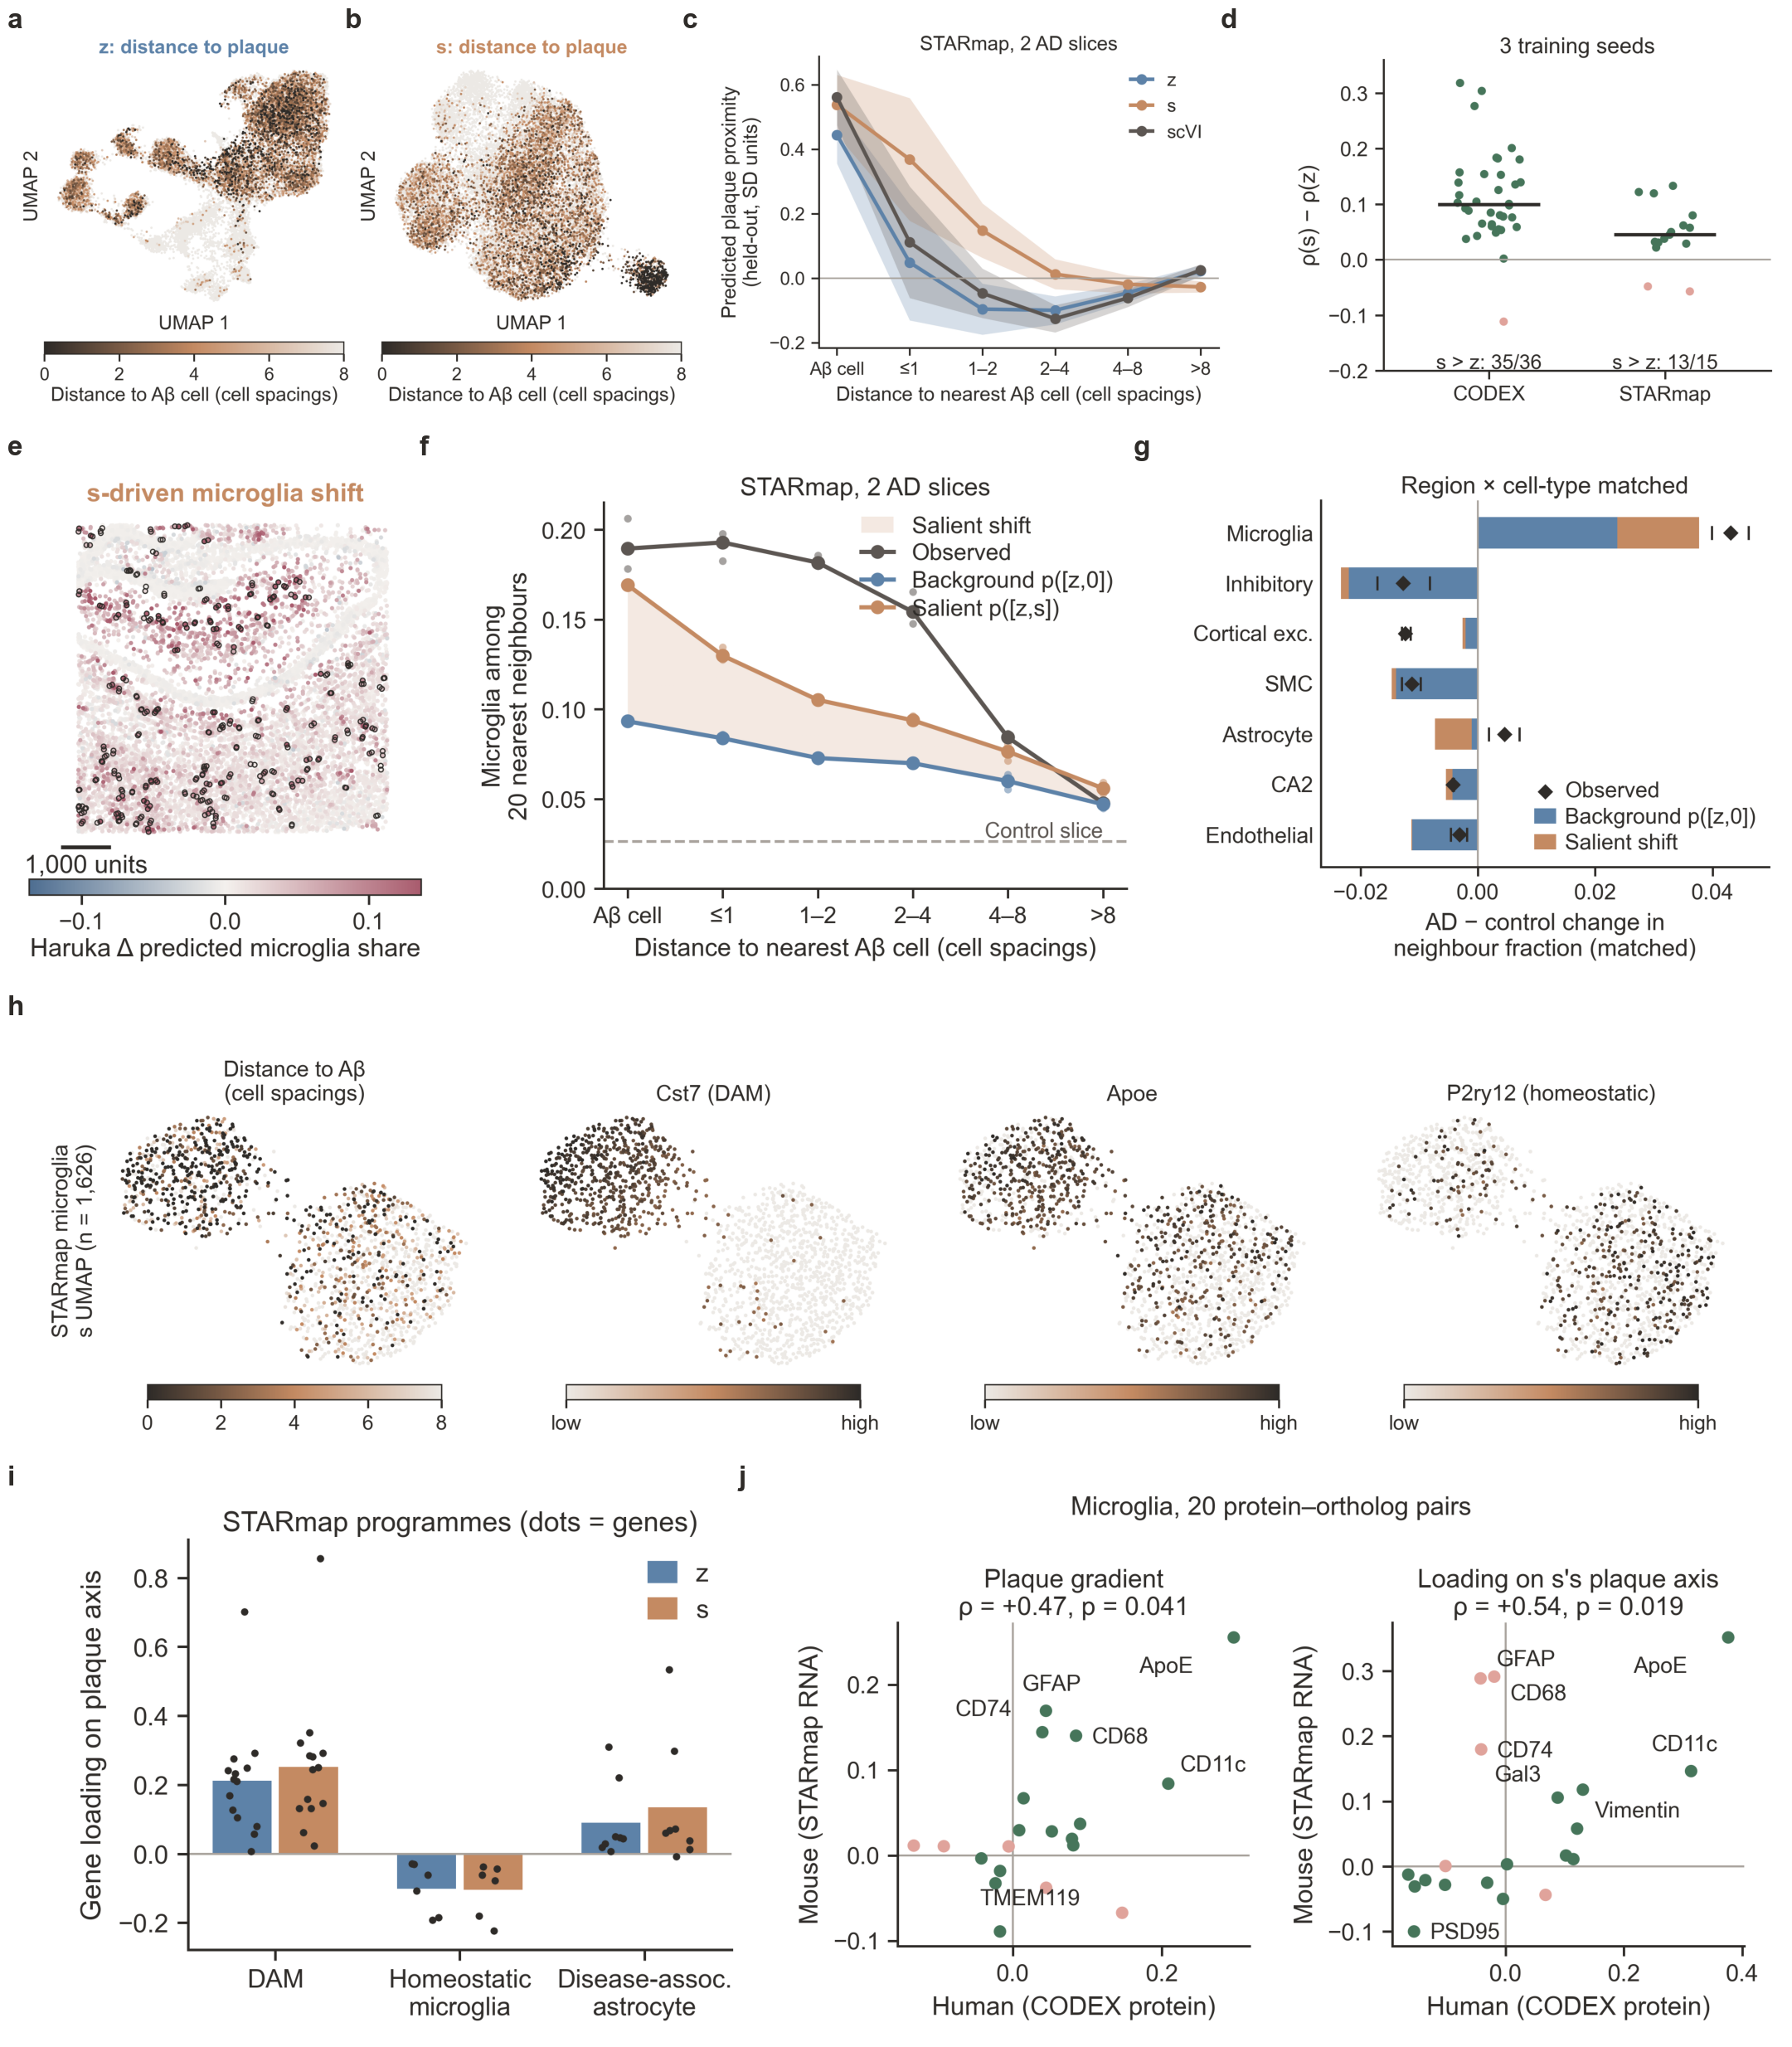

In [7]:
show(H / 'figures_paper/fig3/final/Fig3_full.png')

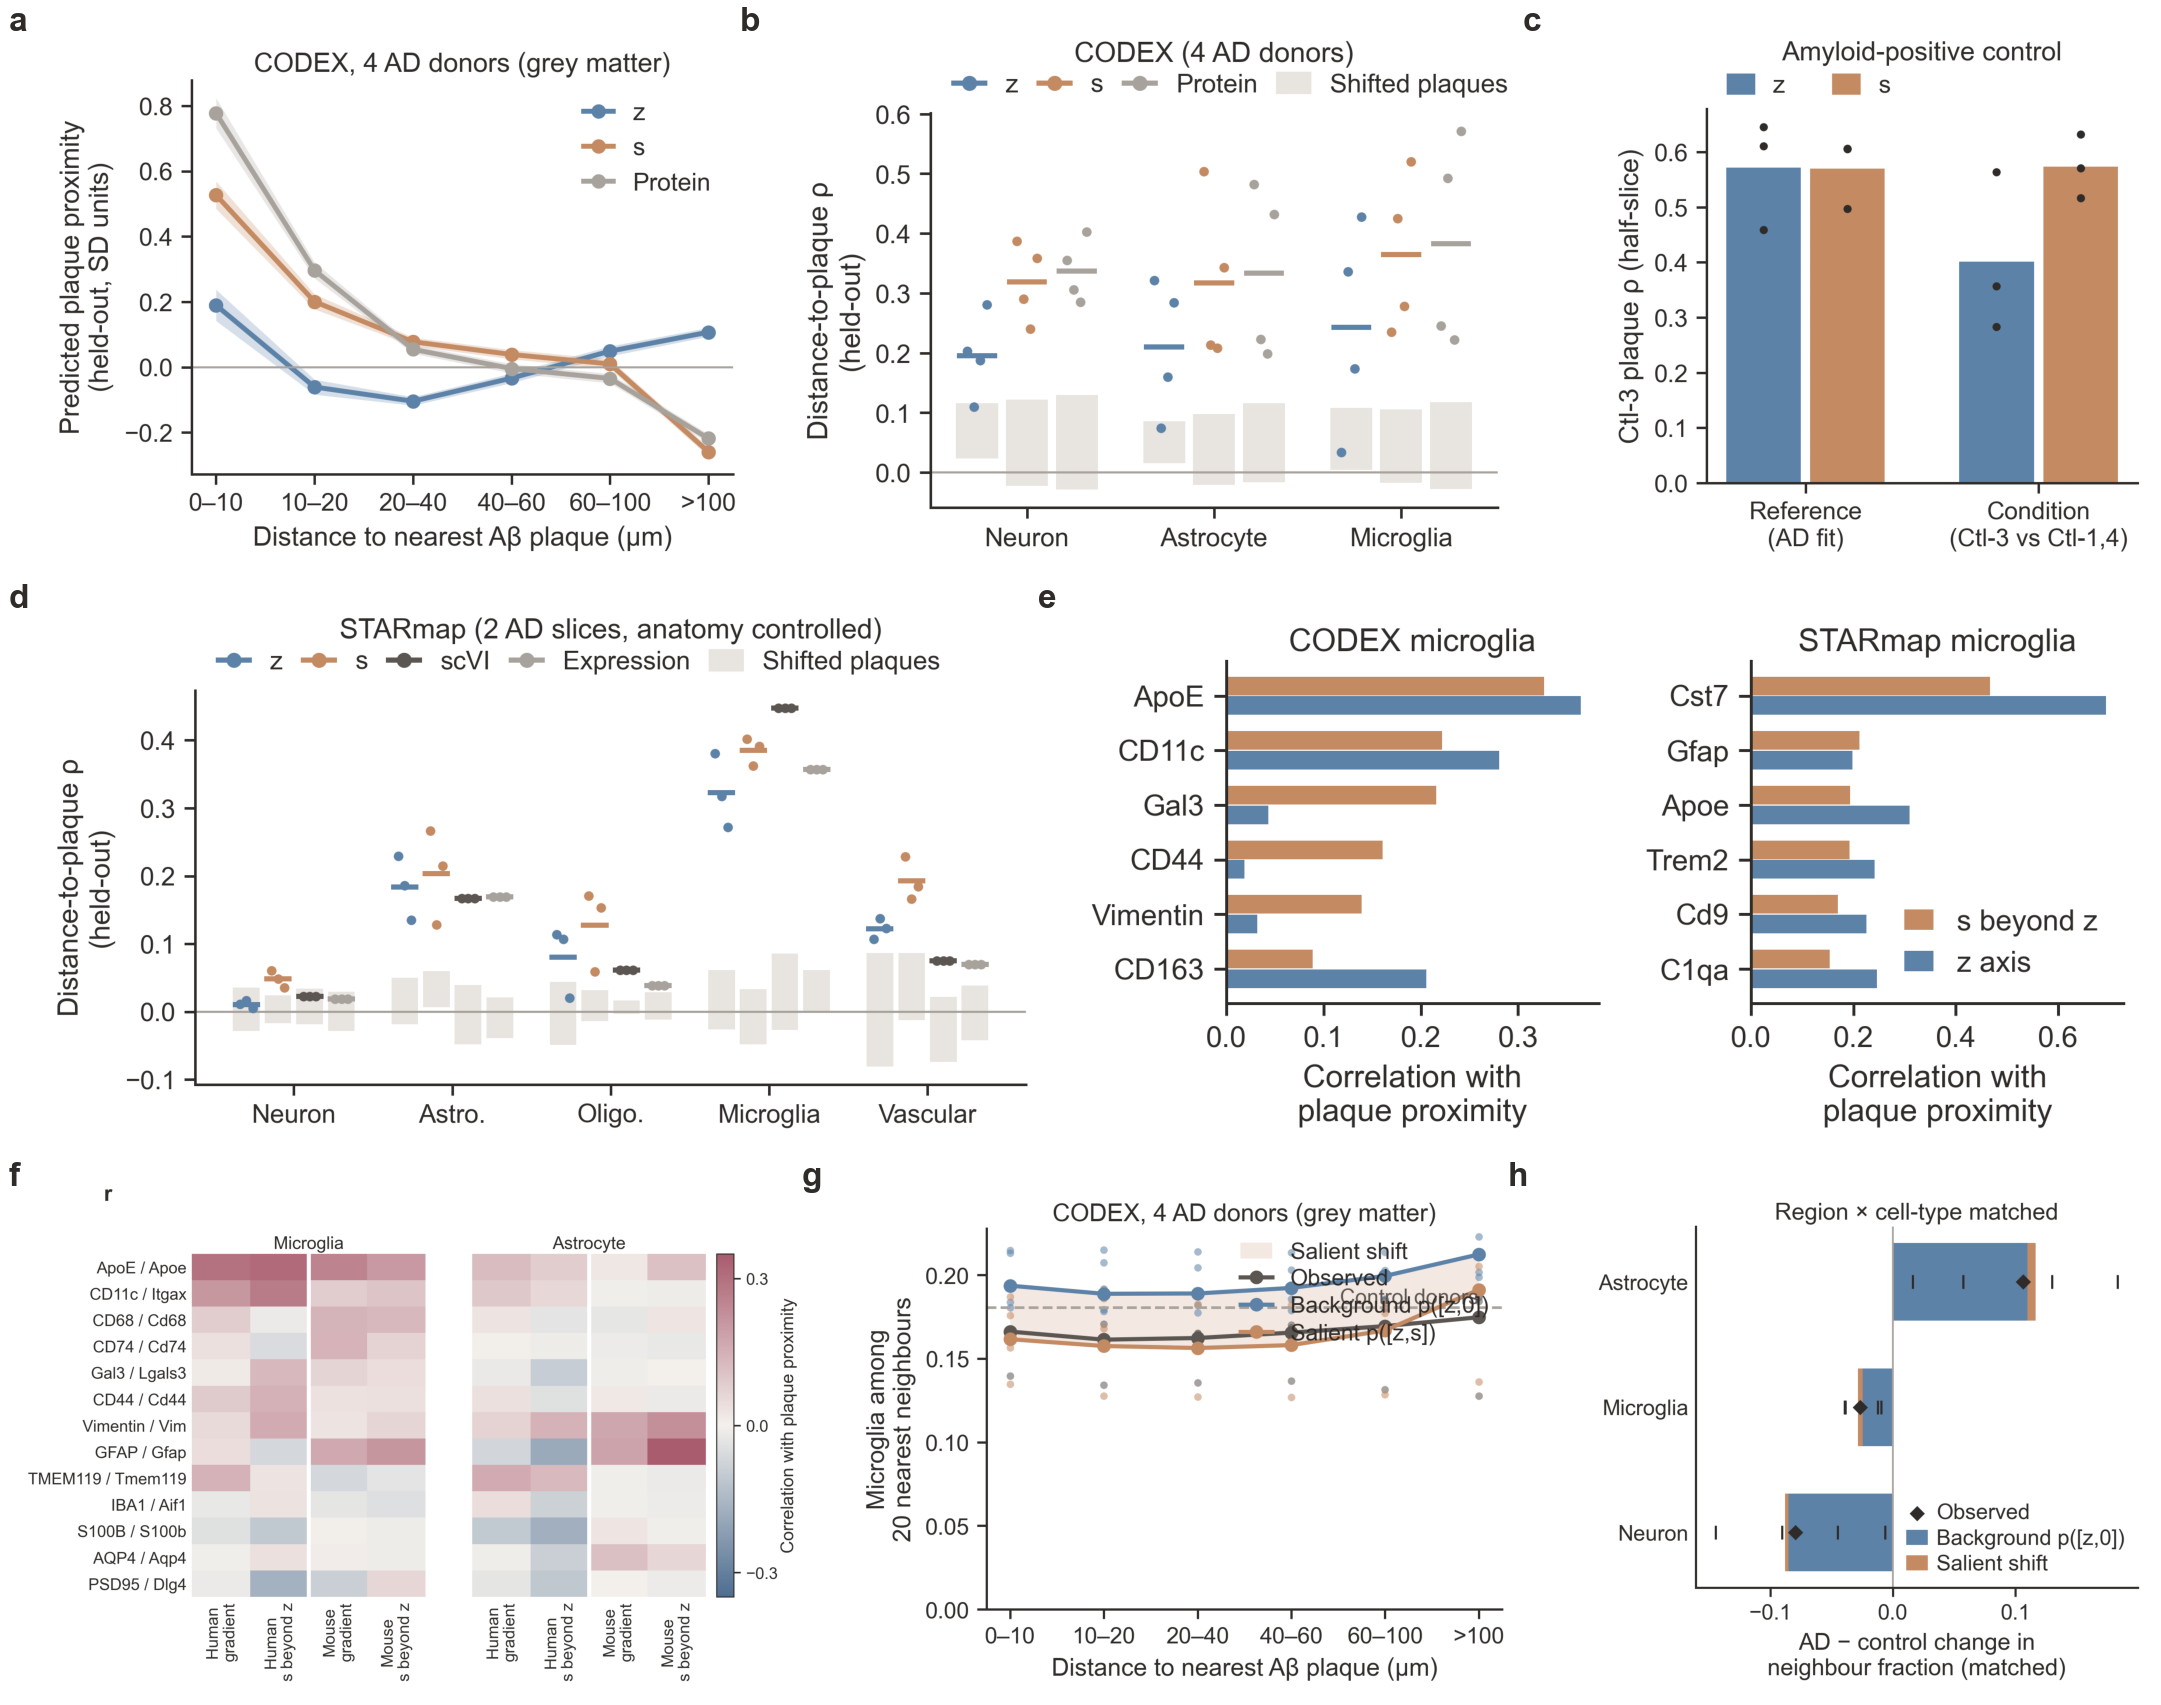

In [8]:
show(H / 'figures_paper/fig3/final/EDFig3_full.png')

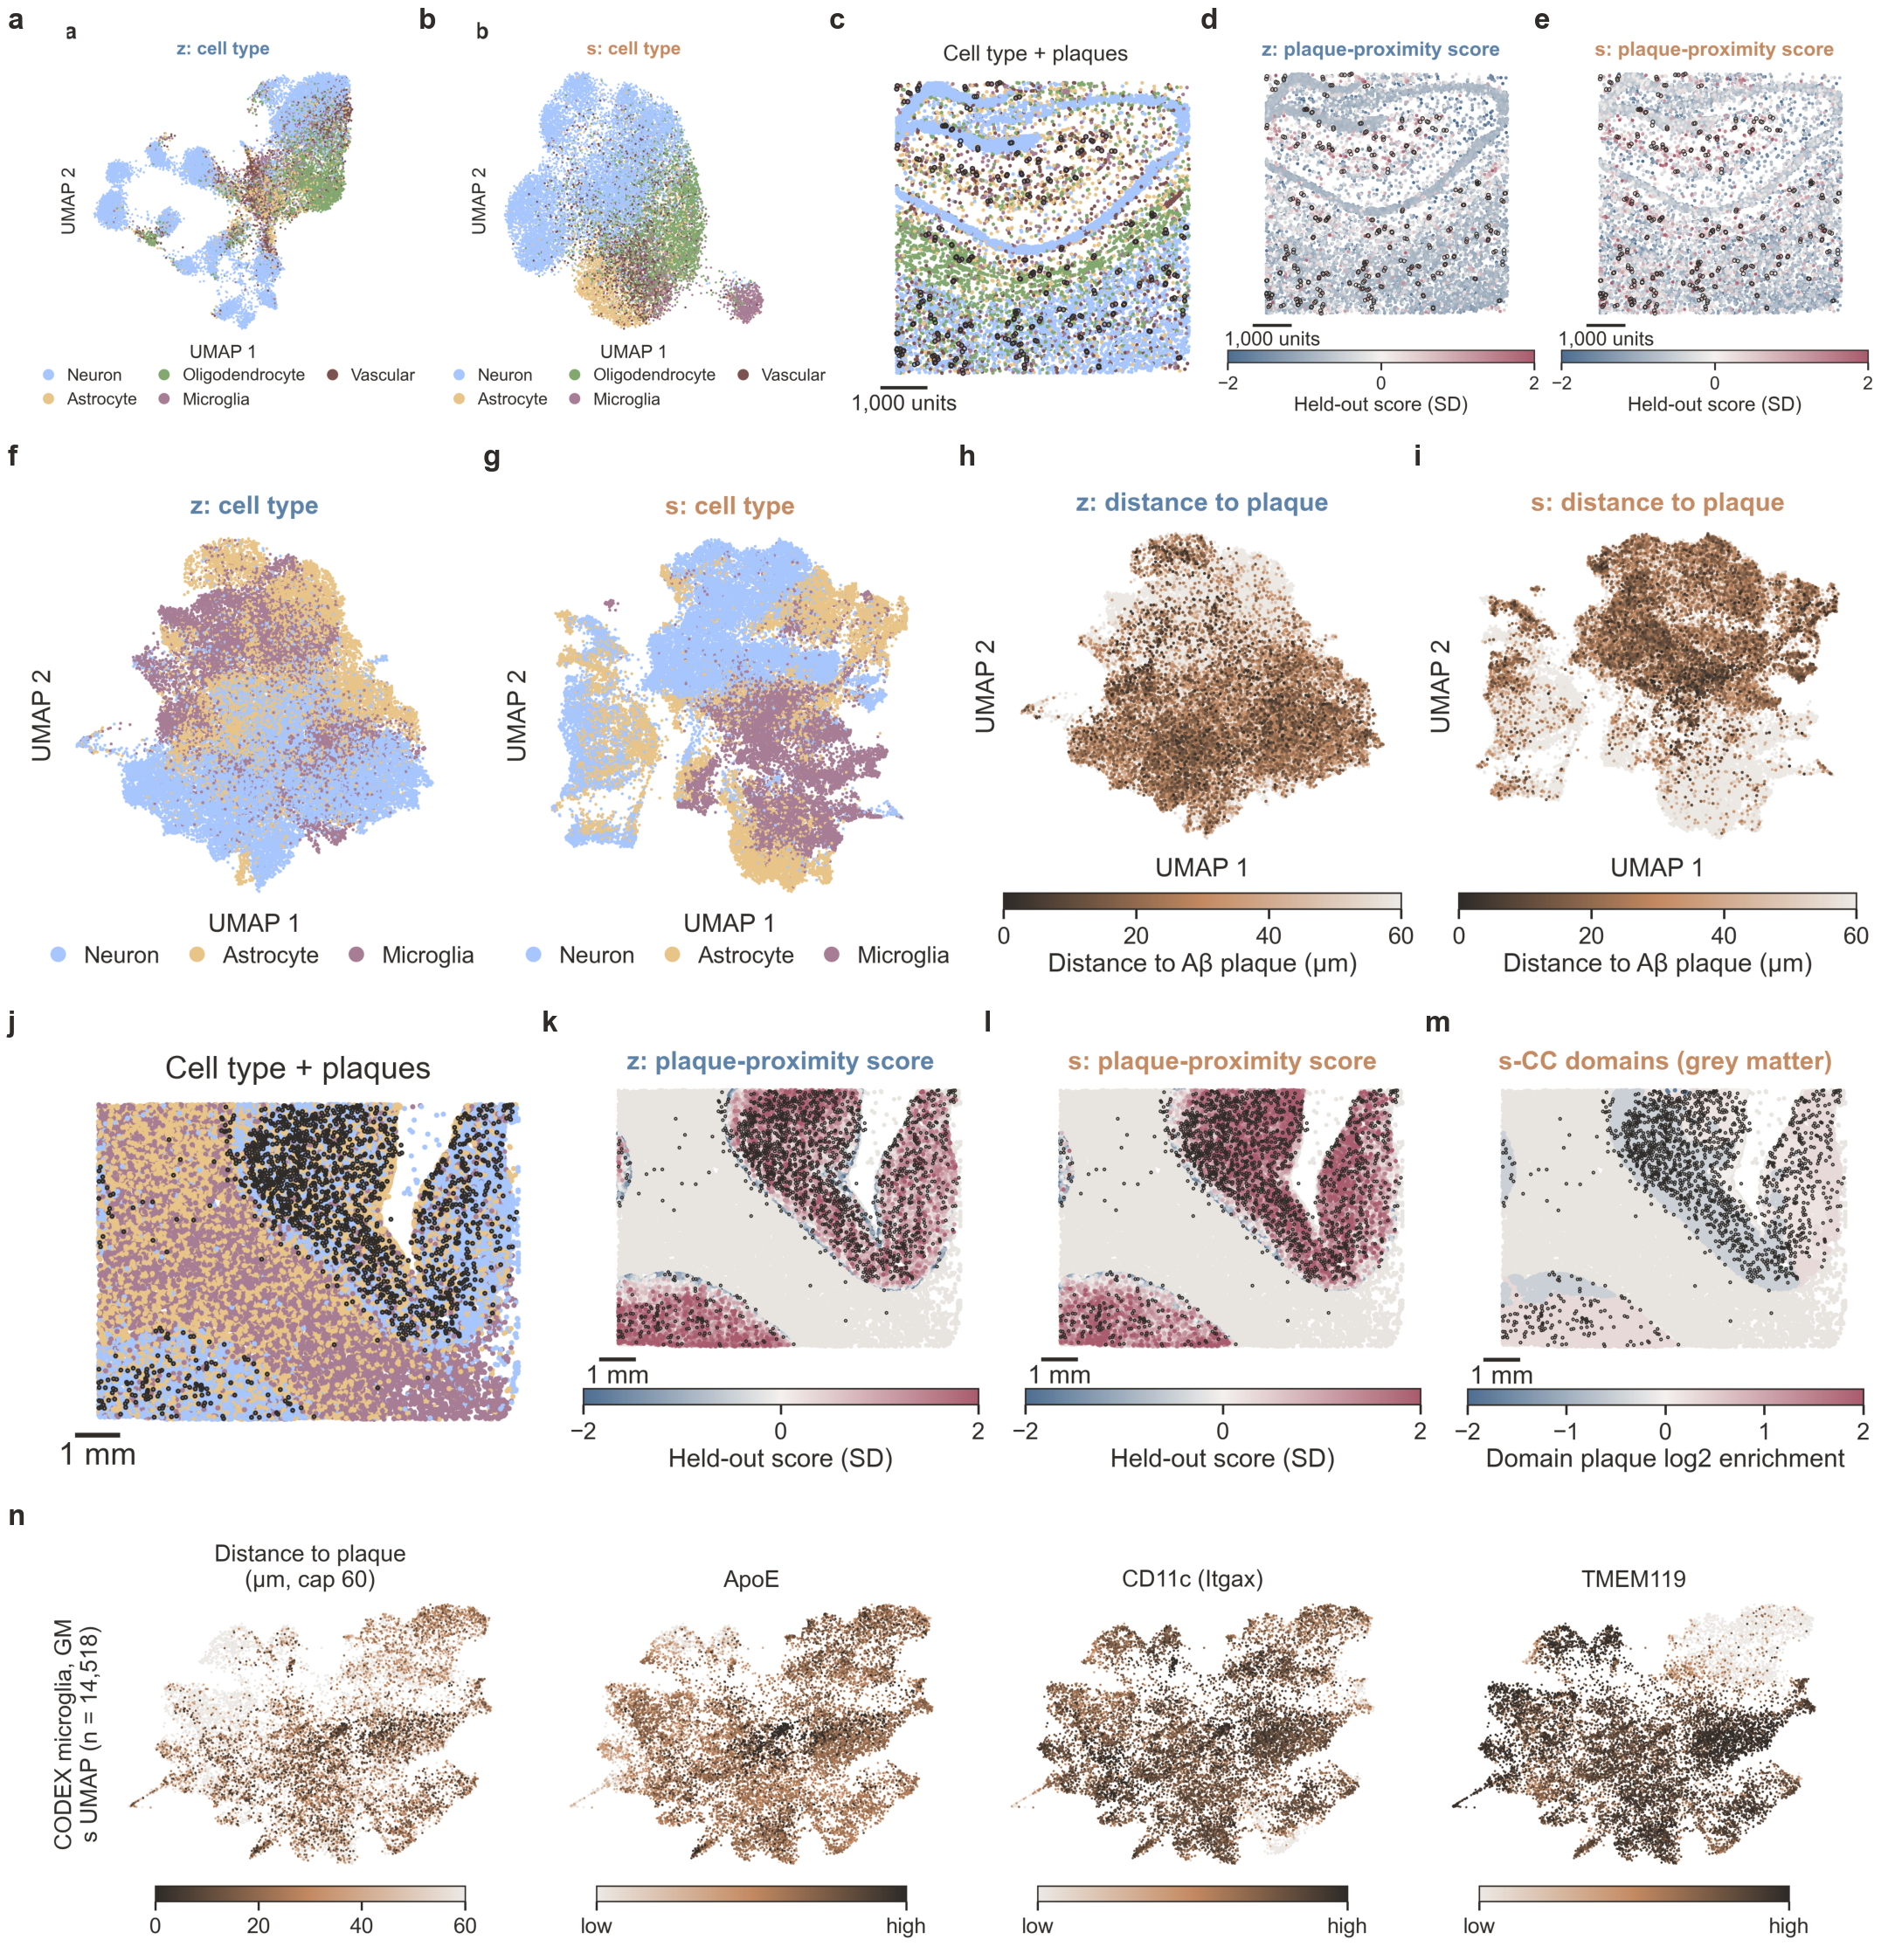

In [9]:
show(H / 'figures_paper/fig3/final/EDFig4_full.png')